# Proyecto Final · Notebook Integral de Ciencia de Datos

### Triaje de enfermedades autoinmunes a partir de un hemograma y un panel inmunológico

| | |
|---|---|
| **Autor** | Emiliano Gandini Outeda |
| **Curso** | Data Science I: Fundamentos para la Ciencia de Datos — Coderhouse |
| **Fecha de entrega** | 19/11/2026 |
| **Repositorio** | [github.com/emiliano-go/autoimmune-disorder-prediction](https://github.com/emiliano-go/autoimmune-disorder-prediction) |
| **Dataset** | [All Autoimmune Disorder 10k](https://www.kaggle.com/datasets/abdullahragheb/all-autoimmune-disorder-10k) (Kaggle) |
| **Tipo de problema** | Clasificación supervisada (binaria) + extensión multiclase + segmentación no supervisada |

---

## Resumen ejecutivo

1. **Problema.** Un laboratorio recibe un hemograma, un panel de autoanticuerpos y un cuestionario
   de síntomas. Antes de derivar al reumatólogo hace falta una primera señal: *¿este paciente
   tiene un cuadro autoinmune o es un estudio normal?* Se modela esa pregunta como clasificación
   binaria (`Normal` vs. `Autoinmune`) sobre 12.500 pacientes y 79 variables.
2. **Hallazgo metodológico central.** El dataset es **sintético** y la etiqueta está codificada en
   las variables por construcción: los 2.500 pacientes `Normal` tienen *todos* los síntomas en cero,
   `Sickness_Duration_Months = 0` y `CRP ≤ 1`, mientras que el panel de anticuerpos falta
   exactamente en esas mismas 2.500 filas. Cualquier modelo razonable llega a **F1 ≈ 1,00**, y eso
   mide al generador de datos, no la capacidad clínica del modelo. El notebook documenta la
   auditoría de esa fuga en lugar de reportar el 1,00 como si fuera un logro.
3. **Modelos.** Regresión Logística y Random Forest, ambos dentro de un `Pipeline` que imputa,
   escala y codifica; umbral de decisión optimizado *out-of-fold* por F1 y validación cruzada
   estratificada de 5 pliegues. La partición train/test se hace **antes** de cualquier ajuste.
4. **Benchmark honesto.** El problema difícil de verdad es el diagnóstico diferencial entre las
   115 enfermedades: con 116 clases el modelo obtiene *accuracy* 0,34 y **macro-F1 0,17**
   (top-3 = 0,36). El resultado es bimodal: **18 enfermedades quedan perfectamente resueltas**
   (tienen un anticuerpo exclusivo) y **84 no se predicen nunca** porque son indistinguibles con
   estas variables. Ahí está el valor futuro del proyecto.
5. **Recomendación.** No desplegar. Usar el pipeline como plantilla de trabajo y validar en una
   cohorte prospectiva real antes de cualquier uso clínico. El clustering sin supervisión
   (K-Means + PCA) recupera la separación `Normal` / `Autoinmune` con una silueta moderada,
   lo que confirma que la estructura dominante del dataset es esa dicotomía y no el diagnóstico fino.

## Cómo reproducir este notebook

```bash
# 1. Dependencias (Python 3.12+)
uv sync

# 2. Datos: el CSV se descarga de Kaggle a data/raw/
uv run download

# 3. Ejecutar de punta a punta
uv run jupyter lab notebooks/06_entrega_final.ipynb
```

El notebook es **autocontenido**: no importa el paquete `src/` del repositorio, define todas sus
funciones y localiza el CSV probando varias rutas (local, `../data/raw`, `/content`) y, como
último recurso, descargándolo con `kagglehub`. Para la entrega se ejecutó con
**Restart Kernel & Run All** y no quedan celdas con error.

> **Convención de fechas:** todas las fechas de este documento están en formato `dd/mm/aaaa`.

In [1]:
# ---------------------------------------------------------------------------
# Configuración global
# ---------------------------------------------------------------------------
import os
import tempfile
import warnings
from pathlib import Path

# Matplotlib necesita un directorio de caché escribible (falla en entornos
# de sólo lectura y en algunos sandboxes de CI).
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "mpl-cache"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    silhouette_score,
    top_k_accuracy_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Semilla y estilo -------------------------------------------------------
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

NORMAL = "#2A6F97"   # azul: pacientes sanos
AUTO = "#E76F51"     # terracota: pacientes autoinmunes
ACCENT = "#2A9D8F"   # verde: destacados
GRAY = "#5C677D"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.dpi": 110,
        "savefig.dpi": 110,
        "axes.titlesize": 12,
        "axes.titleweight": "bold",
        "axes.labelsize": 10,
        "axes.edgecolor": "#C9D1D9",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    }
)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 60)

print(f"pandas {pd.__version__} | numpy {np.__version__} | semilla = {RANDOM_STATE}")

pandas 3.0.5 | numpy 2.5.2 | semilla = 42


---
# 1. Definición del problema y carga de datos

## 1.1 Contexto de negocio

Las enfermedades autoinmunes son un grupo de más de 100 patologías en las que el sistema inmune
ataca tejidos propios. El diagnóstico es notoriamente lento: los síntomas son inespecíficos
(fatiga, dolor articular, febrícula) y se superponen entre enfermedades. En la práctica clínica el
cuello de botella no es el tratamiento sino **la derivación**: distinguir al paciente que necesita
un reumatólogo del que tiene un estudio de laboratorio normal.

Un modelo de triaje útil en ese punto de la cadena tiene que cumplir dos cosas: **alta sensibilidad**
(no dejar pasar un autoinmune) y **trazabilidad** (poder explicar por qué se derivó).

## 1.2 Objetivo y pregunta analítica

> **Pregunta principal:** ¿es posible separar a un paciente `Normal` de uno con alguna enfermedad
> autoinmune usando sólo variables disponibles en una primera consulta (hemograma, reactantes de
> fase aguda, panel de autoanticuerpos y síntomas)?

- **Tarea principal:** clasificación binaria supervisada. `y = 1` si `Diagnosis != "Normal"`.
- **Tarea secundaria:** diagnóstico diferencial entre las 115 enfermedades (116 clases), que es la
  pregunta clínicamente interesante.
- **Tarea complementaria:** segmentación no supervisada para ver si los grupos emergen solos.

### Variables

El dataset mezcla cinco familias de variables:

| Bloque | Variables | Tipo | Uso esperado |
|---|---|---|---|
| Demografía | `Age`, `Gender` | numérica / categórica | contexto, posibles sesgos |
| Hemograma | `RBC_Count`, `Hemoglobin`, `Hematocrit`, `MCV`, `MCH`, `MCHC`, `RDW`, `Reticulocyte_Count`, `WBC_Count`, `Neutrophils`, `Lymphocytes`, `Monocytes`, `Eosinophils`, `Basophils`, `PLT_Count`, `MPV` | continuas | señal fisiológica |
| Reactantes e inmunidad | `CRP`, `ESR`, `C3`, `C4`, `ANA`, `Esbach`, `MBL_Level` | continuas / binaria | inflamación |
| Panel de autoanticuerpos | 50 columnas binarias (`Anti_dsDNA`, `ANCA`, `anti_Scl_70`, …) | binarias | marcadores específicos |
| Síntomas | 10 columnas binarias (`Fatigue or chronic tiredness`, `Joint pain`, …) | binarias | anamnesis |
| Identificadores / fuga | `Patient_ID`, `Sickness_Duration_Months` | — | **excluir** (ver §2.2) |

## 1.3 Ingesta

In [2]:
RAW_NAME = "Autoimmune_Disorder_10k_with_All_Disorders.csv"

# Rutas candidatas: ejecución local desde la raíz del repo, desde notebooks/ o en Colab.
CANDIDATES = [
    Path("data/raw") / RAW_NAME,
    Path("../data/raw") / RAW_NAME,
    Path("/content/data/raw") / RAW_NAME,
]


def load_raw() -> pd.DataFrame:
    '''Carga el CSV original probando rutas locales y, si no existe, Kaggle.'''
    for path in CANDIDATES:
        if path.exists():
            print(f"Dataset encontrado en: {path.resolve()}")
            return pd.read_csv(path)

    print("CSV no encontrado localmente; intentando descarga con kagglehub…")
    try:
        import kagglehub

        downloaded = kagglehub.dataset_download(
            "abdullahragheb/all-autoimmune-disorder-10k",
            path=RAW_NAME,
            output_dir="data/raw",
        )
        print(f"Descargado en: {downloaded}")
        return pd.read_csv(downloaded)
    except Exception as exc:  # pragma: no cover - sólo si falta el archivo
        raise FileNotFoundError(
            "No se encontró el dataset. Descargalo con `uv run download` o a mano desde "
            "https://www.kaggle.com/datasets/abdullahragheb/all-autoimmune-disorder-10k "
            f"y guardalo en data/raw/{RAW_NAME}. Detalle: {exc}"
        ) from exc


df = load_raw()
print(f"\nDimensiones: {df.shape[0]:,} filas x {df.shape[1]} columnas")
df.head(3)

Dataset encontrado en: /home/eclipse/Documents/GitHub/autoimmune-disorder-prediction/data/raw/Autoimmune_Disorder_10k_with_All_Disorders.csv

Dimensiones: 12,500 filas x 79 columnas


,Patient_ID,Age,Gender,Diagnosis,Sickness_Duration_Months,RBC_Count,Hemoglobin,Hematocrit,MCV,MCH,MCHC,RDW,Reticulocyte_Count,WBC_Count,Neutrophils,Lymphocytes,Monocytes,Eosinophils,Basophils,PLT_Count,MPV,ANA,Esbach,MBL_Level,ESR,C3,C4,CRP,Anti-dsDNA,Anti-Sm,...,ASCA,Anti_Ro_SSA,Anti_CBir1,Anti_BP230,Anti_tTG,DGP,Anti_BP180,ASMA,Anti_IF,IgG_IgE_receptor,Anti_SRP,Anti_desmoglein_3,Anti_La_SSB,Anti_Jo1,ANCA,anti_centromere,Anti_desmoglein_1,EMA,Anti_type_VII_collagen,C1_inhibitor,Anti_TIF1,Anti_epidermal_basement_membrane_IgA,Anti_OmpC,pANCA,Anti_tissue_transglutaminase,anti_Scl_70,Anti_Mi2,Anti_parietal_cell,Progesterone_antibodies,Anti_Sm
0,1,65,Female,Linear IgA disease,26,3.54,13.18,44.35,99.85,31.80,33.12,12.52,2.08,8278,72.25,19.80,9.26,4.02,1.08,429117,8.08,1,1.50,1.81,40,1.32,0.49,3.10,1.0,1.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0
1,2,61,Male,Dermatomyositis,106,4.97,14.73,42.39,94.86,29.94,31.07,15.15,1.21,8592,56.73,42.68,2.66,1.67,1.16,487184,8.92,1,1.76,1.08,23,0.40,0.17,2.73,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,1,0,0,0
2,3,42,Male,Ord's thyroiditis,6,3.91,13.66,42.41,88.26,29.43,35.61,15.52,2.68,8719,50.92,31.21,6.96,4.32,1.07,499962,7.70,1,2.49,1.42,44,0.95,0.26,1.02,1.0,0.0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [3]:
# ---------------------------------------------------------------------------
# Ficha técnica del dataset
# ---------------------------------------------------------------------------
numeric_cols = df.select_dtypes(include=np.number).columns
object_cols = [c for c in df.columns if c not in numeric_cols]
binary_cols = [
    c for c in numeric_cols if df[c].dropna().isin([0, 1]).all() and df[c].nunique() == 2
]

ficha = pd.DataFrame(
    {
        "métrica": [
            "Filas",
            "Columnas",
            "Duplicados exactos",
            "Celdas nulas",
            "Columnas numéricas continuas",
            "Columnas binarias (0/1)",
            "Columnas de texto categórico",
            "Clases en `Diagnosis`",
            "Pacientes `Normal`",
            "Pacientes autoinmunes",
        ],
        "valor": [
            f"{df.shape[0]:,}",
            f"{df.shape[1]}",
            f"{df.duplicated().sum()}",
            f"{int(df.isna().sum().sum()):,}",
            f"{len([c for c in numeric_cols if c not in binary_cols])}",
            f"{len(binary_cols)}",
            f"{len(object_cols)}",
            f"{df['Diagnosis'].nunique()}",
            f"{int((df['Diagnosis'] == 'Normal').sum()):,}",
            f"{int((df['Diagnosis'] != 'Normal').sum()):,}",
        ],
    }
)
ficha.set_index("métrica")

,valor
métrica,
Filas,"12,500"
Columnas,79
Duplicados exactos,0
Celdas nulas,"17,500"
Columnas numéricas continuas,26
Columnas binarias (0/1),51
Columnas de texto categórico,2
Clases en `Diagnosis`,116
Pacientes `Normal`,"2,500"


---
# 2. Limpieza y análisis exploratorio

## 2.1 Calidad de datos: nulos, duplicados y tipos

Antes de tocar nada conviene saber qué está roto. En este caso el dataset está **muy limpio en
apariencia**: no hay duplicados, no hay errores de tipo, y los únicos valores faltantes son siete
columnas con exactamente 2.500 nulos cada una. Esa simetría perfecta es la primera pista de que el
dataset no es una cohorte real.

In [4]:
nulos = df.isna().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)

resumen_nulos = pd.DataFrame(
    {
        "columna": nulos.index,
        "nulos": nulos.values,
        "porcentaje": (nulos.values / len(df) * 100).round(1),
        "tipo": df[nulos.index].dtypes.astype(str).values,
    }
)
print("Columnas con valores faltantes:")
display(resumen_nulos)

print(f"\nDuplicados exactos: {df.duplicated().sum()}")
print(f"Filas duplicadas por Patient_ID: {df['Patient_ID'].duplicated().sum()}")
print(f"Tipos: {df.dtypes.astype(str).value_counts().to_dict()}")

Columnas con valores faltantes:


,columna,nulos,porcentaje,tipo
0,Anti-dsDNA,2500,20.0,float64
1,Anti-Sm,2500,20.0,float64
2,Rheumatoid factor,2500,20.0,float64
3,ACPA,2500,20.0,float64
4,Anti-TPO,2500,20.0,float64
5,Anti-Tg,2500,20.0,float64
6,Anti-SMA,2500,20.0,float64



Duplicados exactos: 0
Filas duplicadas por Patient_ID: 0
Tipos: {'int64': 51, 'float64': 26, 'str': 2}


## 2.2 Auditoría de fuga de información (*data leakage*)

Éste es el paso que decide la validez de todo lo que sigue. Antes de entrenar nada, verifico si
alguna variable **contiene** la etiqueta. Cuatro evidencias independientes:

1. **`Sickness_Duration_Months`** vale exactamente `0` en los 2.500 pacientes `Normal` y como
   mínimo `1` en todos los autoinmunes. Es la etiqueta disfrazada de variable.
2. **Los 10 síntomas** valen `0` en el **100%** de los pacientes `Normal`, mientras que 9.896 de los
   10.000 autoinmunes tienen al menos uno en `1`. "Tener algún síntoma" ya es un clasificador casi perfecto.
3. **`CRP`**: los `Normal` nunca superan `1,0 mg/L` mientras que la mediana autoinmune es `5,41`.
4. **El panel de anticuerpos**: las siete columnas con nulos tienen `NaN` en **exactamente** las
   mismas 2.500 filas `Normal`. La ausencia del dato *es* la etiqueta.

Nada de esto es un error del dataset: es cómo fue generado. Pero significa que un F1 de 1,00 no
prueba nada clínicamente. Lo mido, lo documento y lo dejo explícito en las conclusiones.

In [5]:
# --- Evidencia 1: duración de la enfermedad ---------------------------------
dur = df.groupby("Diagnosis")["Sickness_Duration_Months"].agg(
    n="size", minimo="min", maximo="max", mediana="median"
)
print("Duración (meses) — Normal vs. el resto:")
print(
    pd.DataFrame(
        {
            "grupo": ["Normal", "Autoinmune"],
            "n": [2500, 10000],
            "min": [0, int(df.loc[df.Diagnosis != "Normal", "Sickness_Duration_Months"].min())],
            "max": [
                int(df.loc[df.Diagnosis == "Normal", "Sickness_Duration_Months"].max()),
                int(df["Sickness_Duration_Months"].max()),
            ],
        }
    ).to_string(index=False)
)

# --- Evidencia 2: síntomas ---------------------------------------------------
sintomas = [
    "Low-grade fever",
    "Fatigue or chronic tiredness",
    "Dizziness",
    "Weight loss",
    "Rashes and skin lesions",
    "Stiffness in the joints",
    "Brittle hair or hair loss",
    "Dry eyes and/or mouth",
    "General 'unwell' feeling",
    "Joint pain",
]
es_normal = df["Diagnosis"] == "Normal"
tabla_sintomas = pd.DataFrame(
    {
        "síntoma": sintomas,
        "prevalencia en Normal (%)": (df.loc[es_normal, sintomas].mean() * 100).round(1).values,
        "prevalencia en Autoinmune (%)": (df.loc[~es_normal, sintomas].mean() * 100).round(1).values,
    }
)
print("\nPrevalencia de cada síntoma según grupo:")
display(tabla_sintomas)

algun_sintoma = df[sintomas].sum(axis=1) > 0
print(f"\nPacientes Normal con ≥1 síntoma: {int((algun_sintoma & es_normal).sum())} / 2.500")
print(f"Pacientes autoinmunes con ≥1 síntoma: {int((algun_sintoma & ~es_normal).sum())} / 10.000")

# --- Evidencia 3: PCR --------------------------------------------------------
print(
    f"\nCRP — Normal: máx = {df.loc[es_normal, 'CRP'].max():.2f} | "
    f"Autoinmune: mediana = {df.loc[~es_normal, 'CRP'].median():.2f}, mín = {df.loc[~es_normal, 'CRP'].min():.2f}"
)

# --- Evidencia 4: patrón de nulos del panel ---------------------------------
ab7 = ["Anti-dsDNA", "Anti-Sm", "Rheumatoid factor", "ACPA", "Anti-TPO", "Anti-Tg", "Anti-SMA"]
tabla_nulos = pd.crosstab(
    df[ab7].isna().all(axis=1), df["Diagnosis"].eq("Normal"), normalize="index"
).round(3)
tabla_nulos.index = ["Panel medido", "Panel ausente"]
tabla_nulos.columns = ["Autoinmune", "Normal"]
print("\n¿La ausencia del panel coincide con la etiqueta?")
display(tabla_nulos)

Duración (meses) — Normal vs. el resto:
     grupo     n  min  max
    Normal  2500    0    0
Autoinmune 10000    1  119

Prevalencia de cada síntoma según grupo:


,síntoma,prevalencia en Normal (%),prevalencia en Autoinmune (%)
0,Low-grade fever,0.0,50.2
1,Fatigue or chronic tiredness,0.0,48.8
2,Dizziness,0.0,49.2
3,Weight loss,0.0,49.5
4,Rashes and skin lesions,0.0,48.9
5,Stiffness in the joints,0.0,48.8
6,Brittle hair or hair loss,0.0,50.5
7,Dry eyes and/or mouth,0.0,49.8
8,General 'unwell' feeling,0.0,49.3
9,Joint pain,0.0,49.5



Pacientes Normal con ≥1 síntoma: 0 / 2.500
Pacientes autoinmunes con ≥1 síntoma: 9896 / 10.000

CRP — Normal: máx = 1.00 | Autoinmune: mediana = 5.41, mín = 0.03

¿La ausencia del panel coincide con la etiqueta?


,Autoinmune,Normal
Panel medido,1.0,0.0
Panel ausente,0.0,1.0


## 2.3 Decisiones de limpieza

| Columna / problema | Evidencia | Decisión | Motivo |
|---|---|---|---|
| `Patient_ID` | identificador único | **eliminar** | no aporta señal y genera sobreajuste |
| `Sickness_Duration_Months` | `0` en todos los `Normal` | **eliminar** | fuga directa de la etiqueta |
| 7 columnas de anticuerpos con `NaN` (`Anti-dsDNA`, `Anti-Sm`, …) | `NaN` ⟺ `Normal` en el 100% de los casos | **eliminar** | el patrón de faltantes codifica la etiqueta; además duplican parcialmente el panel `Anti_*` |
| `Anti_tTG` | varianza nula (un solo valor) | **eliminar** | no aporta información |
| Resto de nulos | no hay | imputación en el pipeline | preventivo, por si cambia la fuente |

La decisión sobre las siete columnas es la más discutible y la dejo argumentada: imputarlas con `0`
(lo que hacía la limpieza original del repositorio) **no elimina la fuga**, sólo la esconde; el
modelo sigue viendo una diferencia sistemática entre grupos. Eliminarlas es más honesto.

In [6]:
# ---------------------------------------------------------------------------
# Limpieza aplicada
# ---------------------------------------------------------------------------
LEAKY_DURATION = "Sickness_Duration_Months"
LEAKY_PANEL = ["Anti-dsDNA", "Anti-Sm", "Rheumatoid factor", "ACPA", "Anti-TPO", "Anti-Tg", "Anti-SMA"]
CONSTANT_COLS = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]

cols_to_drop = ["Patient_ID", LEAKY_DURATION] + LEAKY_PANEL + CONSTANT_COLS
clean = df.drop(columns=cols_to_drop).copy()

print(f"Columnas eliminadas ({len(cols_to_drop)}): {cols_to_drop}")
print(f"Dimensiones tras limpieza: {clean.shape[0]:,} filas x {clean.shape[1]} columnas")
print(f"Columnas predictoras (sin la etiqueta): {clean.shape[1] - 1}")
print(f"Valores nulos restantes: {clean.isna().sum().sum()}")

Columnas eliminadas (10): ['Patient_ID', 'Sickness_Duration_Months', 'Anti-dsDNA', 'Anti-Sm', 'Rheumatoid factor', 'ACPA', 'Anti-TPO', 'Anti-Tg', 'Anti-SMA', 'Anti_tTG']
Dimensiones tras limpieza: 12,500 filas x 69 columnas
Columnas predictoras (sin la etiqueta): 68
Valores nulos restantes: 0


In [7]:
# ---------------------------------------------------------------------------
# Variable objetivo
# ---------------------------------------------------------------------------
clean["Grupo"] = np.where(clean["Diagnosis"] == "Normal", "Normal", "Autoinmune")
clean["y"] = (clean["Grupo"] == "Autoinmune").astype(int)

conteo = clean["Grupo"].value_counts()
print("Distribución del objetivo binario:")
print((conteo / len(clean) * 100).round(1).to_string(), "\n")
print(f"Ratio de desbalance (autoinmune : normal) = {conteo['Autoinmune'] / conteo['Normal']:.1f} : 1")

print("\nEnfermedades más frecuentes:")
print(clean["Diagnosis"].value_counts().head(10).to_string())

Distribución del objetivo binario:
Grupo
Autoinmune    80.0
Normal        20.0 

Ratio de desbalance (autoinmune : normal) = 4.0 : 1

Enfermedades más frecuentes:
Diagnosis
Normal                       2500
Endometriosis                 184
Dermatomyositis               183
Autoimmune oophoritis         170
Autoimmune orchitis           162
Myasthenia gravis             149
Hidradenitis suppurativa      101
Dermatitis herpetiformis      101
Vasculitis                    101
Antiphospholipid syndrome     101


## 2.4 Visualizaciones del EDA

### Gráfico 1 · Balance de clases y composición del diagnóstico

Dos problemas distintos en una sola figura: el desbalance binario (80/20) y la enorme
fragmentación del diagnóstico fino (115 de las 116 clases tienen menos de 200 casos).

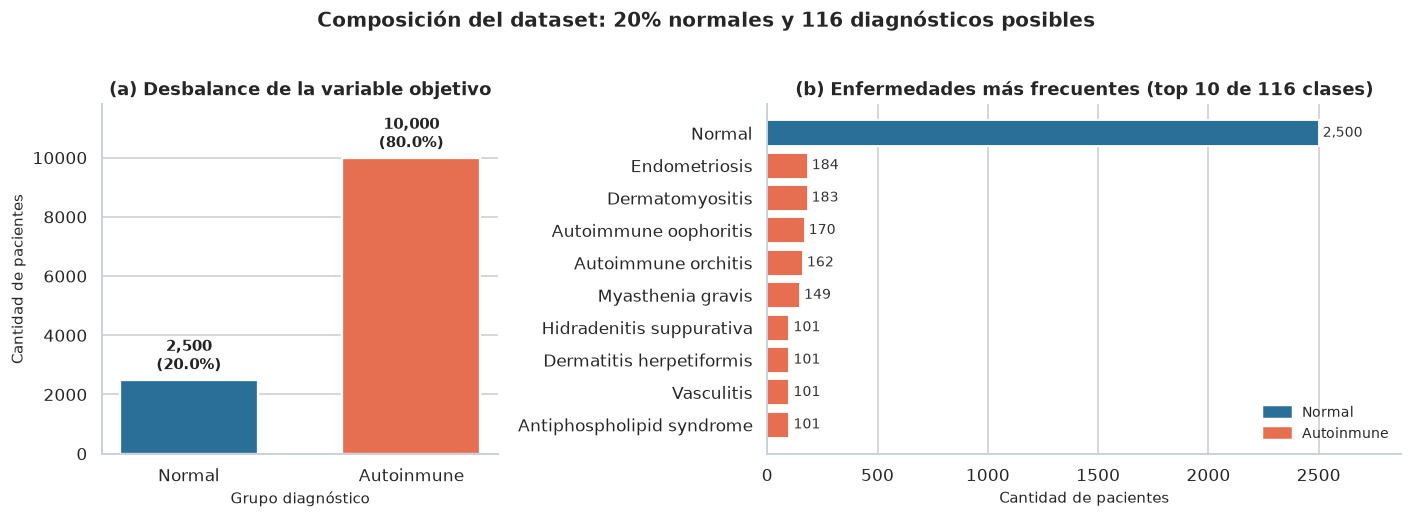

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.6]})

# (a) balance binario
ax = axes[0]
orden = ["Normal", "Autoinmune"]
valores = [clean["Grupo"].eq(g).sum() for g in orden]
barras = ax.bar(orden, valores, color=[NORMAL, AUTO], width=0.62, edgecolor="white", linewidth=1.5)
for barra, valor in zip(barras, valores):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        valor + 180,
        f"{valor:,}\n({valor / len(clean):.1%})",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
        color="#222222",
    )
ax.set_title("(a) Desbalance de la variable objetivo")
ax.set_xlabel("Grupo diagnóstico")
ax.set_ylabel("Cantidad de pacientes")
ax.set_ylim(0, max(valores) * 1.18)
ax.grid(axis="x", visible=False)

# (b) top 10 enfermedades
ax = axes[1]
top = clean["Diagnosis"].value_counts().head(10)[::-1]
colores = [NORMAL if nombre == "Normal" else AUTO for nombre in top.index]
ax.barh(top.index, top.values, color=colores, edgecolor="white", linewidth=1.2)
for i, valor in enumerate(top.values):
    ax.text(valor + 18, i, f"{valor:,}", va="center", fontsize=9, color="#333333")
ax.set_title("(b) Enfermedades más frecuentes (top 10 de 116 clases)")
ax.set_xlabel("Cantidad de pacientes")
ax.set_ylabel("")
ax.set_xlim(0, top.max() * 1.15)
ax.grid(axis="y", visible=False)

from matplotlib.patches import Patch

axes[1].legend(
    handles=[Patch(color=NORMAL, label="Normal"), Patch(color=AUTO, label="Autoinmune")],
    loc="lower right",
    frameon=False,
    fontsize=9,
)

fig.suptitle(
    "Composición del dataset: 20% normales y 116 diagnósticos posibles",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
plt.show()

**Lectura.** El 20% `Normal` fija el piso de cualquier métrica ingenua: un modelo que diga siempre
"autoinmune" ya acierta el 80% de las filas, pero con F1 = 0. Por eso el *accuracy* solo no sirve
como criterio y de acá en adelante se reporta **F1, recall y PR-AUC**. El panel (b) muestra la otra
dificultad: el diagnóstico fino está muy fragmentado, con clases de 50 a 184 casos, lo que hace que
el problema multiclase sea estadísticamente mucho más exigente que el binario.

### Gráfico 2 · PCR: el marcador que delata el diseño del dataset

La proteína C reactiva (PCR/CRP) es el reactante de fase aguda más usado en la práctica. Si el
dataset fuera una cohorte real, esperaría una distribución continua y solapada entre grupos.

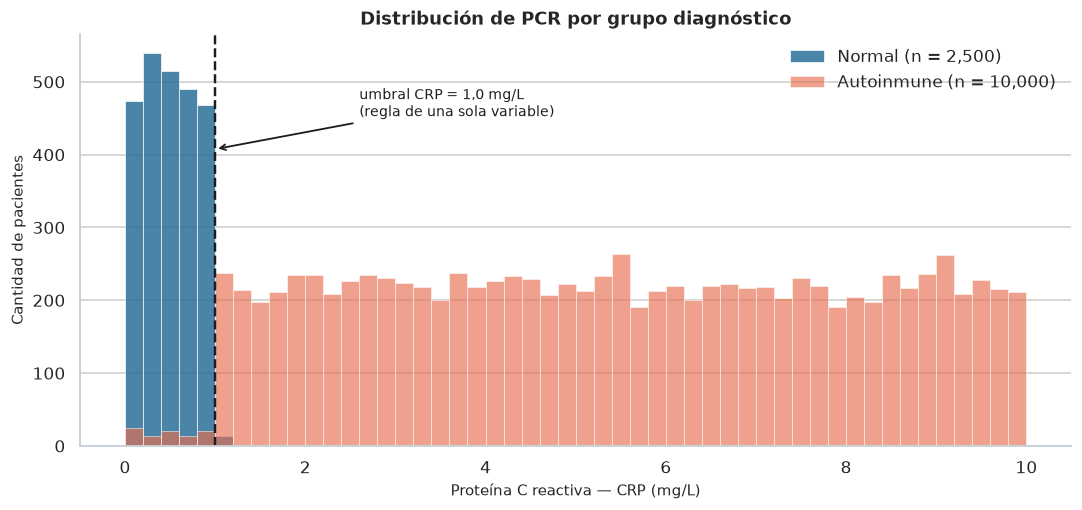

Normal     → CRP máx = 1.00 mg/L
Autoinmune → CRP mediana = 5.41 mg/L
Autoinmunes con CRP ≤ 1: 101


In [9]:
fig, ax = plt.subplots(figsize=(10, 4.8))

bins = np.linspace(0, 10, 51)
ax.hist(
    clean.loc[clean.Grupo == "Normal", "CRP"],
    bins=bins,
    color=NORMAL,
    alpha=0.85,
    label=f"Normal (n = {int(clean.Grupo.eq('Normal').sum()):,})",
    edgecolor="white",
    linewidth=0.5,
)
ax.hist(
    clean.loc[clean.Grupo == "Autoinmune", "CRP"],
    bins=bins,
    color=AUTO,
    alpha=0.65,
    label=f"Autoinmune (n = {int(clean.Grupo.eq('Autoinmune').sum()):,})",
    edgecolor="white",
    linewidth=0.5,
)
ax.axvline(1.0, color="#1D1D1D", linestyle="--", linewidth=1.6)
ax.annotate(
    "umbral CRP = 1,0 mg/L\n(regla de una sola variable)",
    xy=(1.0, ax.get_ylim()[1] * 0.72),
    xytext=(2.6, ax.get_ylim()[1] * 0.80),
    fontsize=9,
    color="#1D1D1D",
    arrowprops=dict(arrowstyle="->", color="#1D1D1D", linewidth=1.2),
)
ax.set_title("Distribución de PCR por grupo diagnóstico")
ax.set_xlabel("Proteína C reactiva — CRP (mg/L)")
ax.set_ylabel("Cantidad de pacientes")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

print(f"Normal     → CRP máx = {clean.loc[clean.Grupo == 'Normal', 'CRP'].max():.2f} mg/L")
print(f"Autoinmune → CRP mediana = {clean.loc[clean.Grupo == 'Autoinmune', 'CRP'].median():.2f} mg/L")
print(f"Autoinmunes con CRP ≤ 1: {int((clean.loc[clean.Grupo == 'Autoinmune', 'CRP'] <= 1).sum()):,}")

**Lectura.** Las dos distribuciones están prácticamente **disjuntas**: ningún paciente `Normal`
supera 1,0 mg/L y apenas ~1% de los autoinmunes queda por debajo. Es exactamente lo contrario de lo
que se ve en datos reales (donde la PCR se solapa porque también sube con infecciones, obesidad o
tabaquismo). Esta figura es la prueba visual de que el dataset fue generado con una regla. La
consecuencia práctica: **una única variable resuelve el problema binario**, y así lo confirmo en
la escalera de baselines del §4.

### Gráfico 3 · Perfil hematológico: anemia e inflamación crónica

Si hay una señal fisiológicamente defendible, es ésta: la anemia de enfermedad crónica baja
hemoglobina y hematocrito, y sube el RDW (anisocitosis). Vale la pena verla.

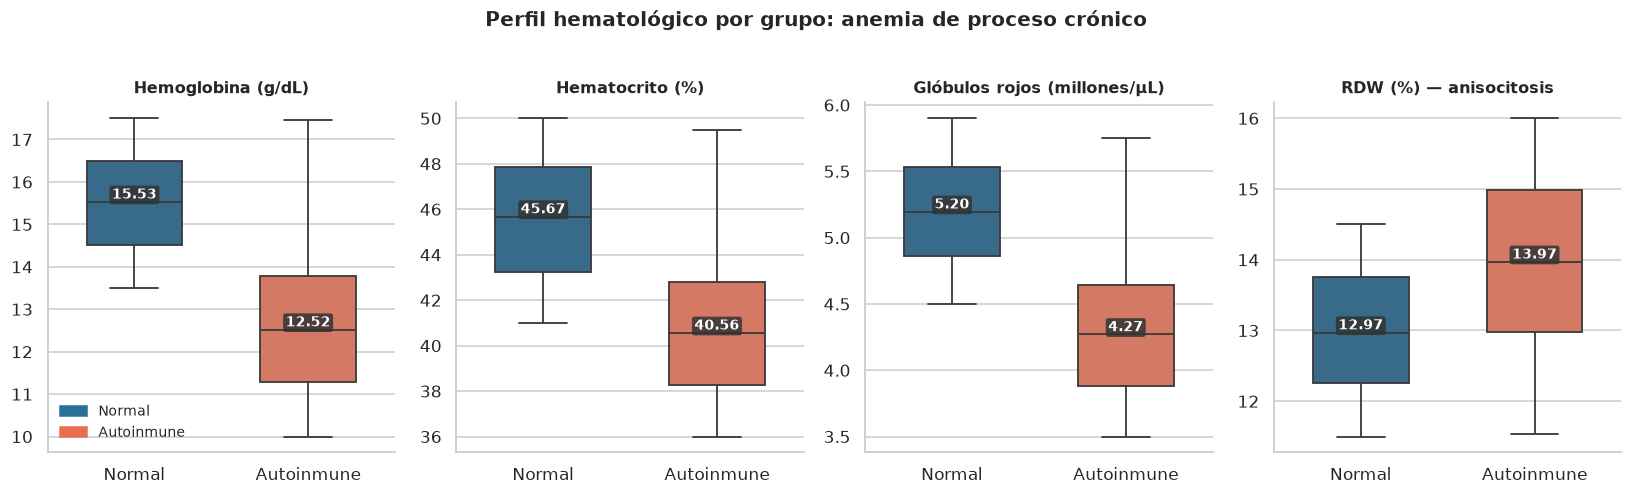

Grupo,Autoinmune,Normal,diferencia (%)
Hemoglobin,12.52,15.53,-19.4
Hematocrit,40.56,45.68,-11.2
RBC_Count,4.27,5.20,-17.9
RDW,13.97,12.97,7.7


In [10]:
perfil = ["Hemoglobin", "Hematocrit", "RBC_Count", "RDW"]
titulos = [
    "Hemoglobina (g/dL)",
    "Hematocrito (%)",
    "Glóbulos rojos (millones/µL)",
    "RDW (%) — anisocitosis",
]

fig, axes = plt.subplots(1, 4, figsize=(15, 4.4))
for ax, col, titulo in zip(axes, perfil, titulos):
    sns.boxplot(
        data=clean,
        x="Grupo",
        y=col,
        hue="Grupo",
        order=["Normal", "Autoinmune"],
        hue_order=["Normal", "Autoinmune"],
        palette={"Normal": NORMAL, "Autoinmune": AUTO},
        width=0.55,
        linewidth=1.2,
        fliersize=1.6,
        flierprops={"alpha": 0.25, "markeredgewidth": 0},
        legend=False,
        ax=ax,
    )
    medianas = clean.groupby("Grupo")[col].median()
    ax.set_title(titulo, fontsize=10.5)
    ax.set_xlabel("")
    ax.set_ylabel("")
    for i, grupo in enumerate(["Normal", "Autoinmune"]):
        ax.text(
            i,
            medianas[grupo],
            f"{medianas[grupo]:.2f}",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold",
            color="white",
            bbox=dict(boxstyle="round,pad=0.18", facecolor="#333333", edgecolor="none", alpha=0.85),
        )
    ax.grid(axis="x", visible=False)

axes[0].legend(
    handles=[Patch(color=NORMAL, label="Normal"), Patch(color=AUTO, label="Autoinmune")],
    frameon=False,
    loc="lower left",
    fontsize=9,
)
fig.suptitle(
    "Perfil hematológico por grupo: anemia de proceso crónico",
    fontsize=13,
    fontweight="bold",
    y=1.02,
)
fig.tight_layout()
plt.show()

tabla_perfil = clean.groupby("Grupo")[perfil].median().T.round(2)
tabla_perfil["diferencia (%)"] = (
    (tabla_perfil["Autoinmune"] - tabla_perfil["Normal"]) / tabla_perfil["Normal"] * 100
).round(1)
tabla_perfil

**Lectura.** El grupo autoinmune tiene hemoglobina mediana de 12,5 g/dL contra 15,5 del grupo
normal (−19%), hematocrito 10% más bajo y RDW 1 punto más alto. Es el patrón clásico de **anemia
normocítica por inflamación crónica**, y es la única familia de variables cuya dirección tiene una
explicación fisiológica plausible. Aun así, la separación vuelve a ser demasiado limpia para ser
real: en una cohorte clínica habría pacientes normales anémicos por otras causas.

### Gráfico 4 · Matriz de correlación: qué se mueve junto

Sirve para dos cosas: detectar colinealidad (relevante para la Regresión Logística) y ver si hay
bloques de variables que midan lo mismo.

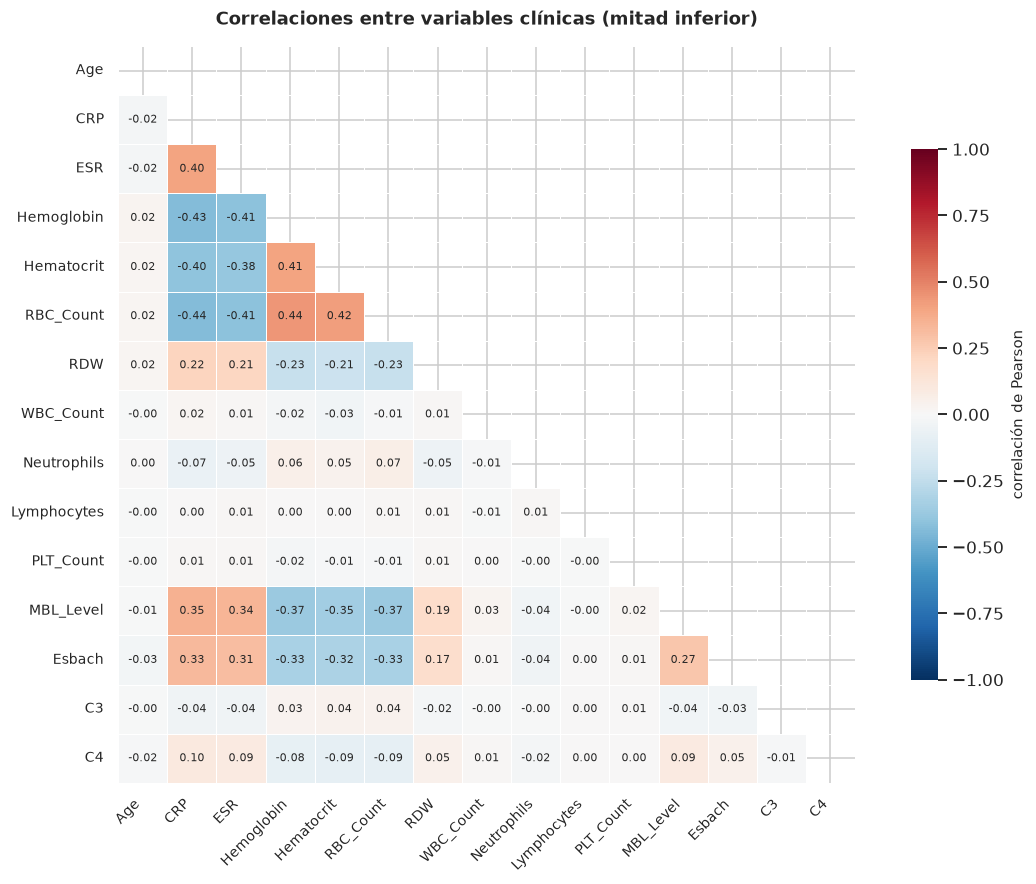

In [11]:
vars_corr = [
    "Age",
    "CRP",
    "ESR",
    "Hemoglobin",
    "Hematocrit",
    "RBC_Count",
    "RDW",
    "WBC_Count",
    "Neutrophils",
    "Lymphocytes",
    "PLT_Count",
    "MBL_Level",
    "Esbach",
    "C3",
    "C4",
]
corr = clean[vars_corr].corr(method="pearson")

fig, ax = plt.subplots(figsize=(11, 8.2))
mascara = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr,
    mask=mascara,
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={"shrink": 0.72, "label": "correlación de Pearson"},
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7.5},
    ax=ax,
)
ax.set_title("Correlaciones entre variables clínicas (mitad inferior)", pad=14)
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=9)
fig.tight_layout()
plt.show()

**Lectura.** Tres bloques claros:

- **Hemograma**: `Hemoglobin`–`Hematocrit` (0,90) y `Hemoglobin`–`RBC_Count` (0,83). Son casi la
  misma variable medida de tres formas; la colinealidad es severa y conviene saberlo antes de
  interpretar los coeficientes de una Regresión Logística.
- **Inflamación**: `CRP`–`ESR` suben juntas y ambas correlacionan negativo con hemoglobina
  (−0,35 y −0,30): inflamación crónica y anemia van de la mano.
- Nada correlaciona fuerte con la edad, que funciona como variable de contexto y no de señal.

La consecuencia metodológica: para un modelo lineal conviene regularizar y leer los coeficientes con
pinzas; el Random Forest tolera la colinealidad sin problema.

## 2.5 Valores atípicos: ¿limpiar o conservar?

Regla usada: valores fuera del rango `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]` por columna **continua**.

In [12]:
def conteo_outliers(frame: pd.DataFrame, columnas: list[str]) -> pd.DataFrame:
    filas = []
    for col in columnas:
        q1, q3 = frame[col].quantile([0.25, 0.75])
        iqr = q3 - q1
        bajo, alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n = int(((frame[col] < bajo) | (frame[col] > alto)).sum())
        filas.append(
            {
                "variable": col,
                "Q1": round(q1, 2),
                "Q3": round(q3, 2),
                "límite inferior": round(bajo, 2),
                "límite superior": round(alto, 2),
                "outliers": n,
                "% del total": round(n / len(frame) * 100, 2),
            }
        )
    return pd.DataFrame(filas).sort_values("outliers", ascending=False)


continuas = [
    "Age", "RBC_Count", "Hemoglobin", "Hematocrit", "MCV", "MCH", "MCHC", "RDW",
    "Reticulocyte_Count", "WBC_Count", "Neutrophils", "Lymphocytes", "Monocytes",
    "Eosinophils", "Basophils", "PLT_Count", "MPV", "CRP", "ESR", "C3", "C4",
    "Esbach", "MBL_Level",
]
tabla_outliers = conteo_outliers(clean, continuas)
print(f"Total de valores atípicos detectados: {int(tabla_outliers['outliers'].sum()):,}")
tabla_outliers.head(8).round(2)

Total de valores atípicos detectados: 0


,variable,Q1,Q3,límite inferior,límite superior,outliers,% del total
0,Age,34.00,65.00,-12.50,111.50,0,0.0
1,RBC_Count,3.98,4.83,2.71,6.11,0,0.0
2,Hemoglobin,11.61,14.41,7.41,18.61,0,0.0
3,Hematocrit,38.88,43.81,31.49,51.20,0,0.0
4,MCV,83.39,97.06,62.88,117.57,0,0.0
5,MCH,27.69,30.38,23.65,34.42,0,0.0
6,MCHC,32.43,34.83,28.83,38.43,0,0.0
7,RDW,12.80,14.72,9.92,17.60,0,0.0


**Resultado: cero valores atípicos en las 23 variables continuas.** Es un resultado raro y vale
como evidencia adicional del origen sintético: las distribuciones están **acotadas por diseño**
(la PCR nunca pasa de 10 mg/L, la hemoglobina se mueve en una banda estrecha), así que los bigotes
de Tukey no encuentran nada que marcar.

Un detalle metodológico que conviene explicitar: si la misma regla se aplicara a las columnas
binarias, el IQR sería `0` y **todos los `1` quedarían marcados como atípicos**. Eso no es un dato
raro, es un artefacto de aplicar un criterio pensado para distribuciones continuas a variables
0/1 — y es una fuente clásica de errores en informes de limpieza.

**Decisión: no se elimina ninguna fila.** No hay nada que eliminar; y en el caso hipotético de que
hubiera valores extremos, se conservarían porque en triaje los casos extremos son justamente los
que importan. Lo que sí se hace es **escalar** las numéricas dentro del pipeline, para que la
escala no distorsione ni la Regresión Logística ni el cálculo de distancias.

## 2.6 Síntesis del EDA

| # | Hallazgo | Implicancia |
|---|---|---|
| 1 | Desbalance 80/20 | usar F1 / recall / PR-AUC, no accuracy |
| 2 | 116 clases con 62–184 casos | el multiclase es el problema difícil |
| 3 | `CRP` casi disjunta entre grupos | una regla de una variable llega a F1 0,99 |
| 4 | Síntomas en cero en el 100% de los `Normal` | fuga estructural de la etiqueta |
| 5 | Duración `= 0` en todos los `Normal` | fuga directa → se elimina |
| 6 | Colinealidad fuerte en el hemograma | regularizar / preferir árboles |
| 7 | Sin outliers en variables continuas (distribuciones acotadas) | evidencia extra de origen sintético |

Con esto queda claro que **el techo del problema binario no es 1,00 en la realidad, aunque en este
dataset lo sea**. El resto del notebook está diseñado para probarlo, no para lucir el número.

---
# 3. Preprocesamiento y *feature engineering*

## 3.1 Partición train / test — antes de cualquier ajuste

Regla de oro contra el *data leakage*: **la partición va primero**. Cualquier cosa que se estime a
partir de los datos (medianas de imputación, medias y desvíos del escalado, categorías del one-hot)
se ajusta **sólo con train**. Acá se hace con un `Pipeline` de scikit-learn, que garantiza que el
`fit` del preprocesador ocurra dentro de cada pliegue de validación y no sobre el total.

In [13]:
X = clean.drop(columns=["Diagnosis", "Grupo", "y"])
y = clean["y"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {X_train.shape[0]:,} filas ({y_train.mean():.1%} positivos)")
print(f"Test : {X_test.shape[0]:,} filas ({y_test.mean():.1%} positivos)")
print(f"Columnas predictoras: {X_train.shape[1]}")
print("\nLa estratificación preserva la proporción de clases en ambos conjuntos.")

Train: 10,000 filas (80.0% positivos)
Test : 2,500 filas (80.0% positivos)
Columnas predictoras: 68

La estratificación preserva la proporción de clases en ambos conjuntos.


## 3.2 *Feature engineering*

Tres variables derivadas, todas **calculadas fila por fila** (no usan información del conjunto, así
que no introducen fuga):

| Variable | Fórmula | Justificación clínica |
|---|---|---|
| `NLR` | `Neutrophils / Lymphocytes` | índice neutrófilo-linfocito: marcador de inflamación sistémica ampliamente usado y gratuito (sale del mismo hemograma) |
| `Anemia` | `1` si Hb < 12 (mujeres) / < 13 (hombres) | operacionaliza el hallazgo del Gráfico 3 con umbrales OMS |
| `Sintomas_total` | suma de los 10 síntomas (0–10) | carga sintomática como *score* de severidad |

`Sintomas_total` es, además, la variable que **expone la fuga** de forma más directa: vale 0 en
todos los `Normal`. Se incluye a propósito y se comenta en la importancia de variables.

In [14]:
def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    '''Agrega variables derivadas. Opera fila a fila: no usa información del conjunto.'''
    out = frame.copy()
    out["NLR"] = out["Neutrophils"] / out["Lymphocytes"].replace(0, np.nan)
    umbral_hb = np.where(out["Gender"] == "Female", 12.0, 13.0)
    out["Anemia"] = (out["Hemoglobin"] < umbral_hb).astype(int)
    out["Sintomas_total"] = out[sintomas].sum(axis=1)
    return out


X_train_fe = add_features(X_train)
X_test_fe = add_features(X_test)

nuevas = ["NLR", "Anemia", "Sintomas_total"]
print("Variables creadas:", nuevas)
print(f"\nColumnas finales: {X_train_fe.shape[1]}")
display(X_train_fe[nuevas].describe().T.round(2))

Variables creadas: ['NLR', 'Anemia', 'Sintomas_total']

Columnas finales: 71


,count,mean,std,min,25%,50%,75%,max
NLR,10000.0,1.92,0.74,0.68,1.4,1.78,2.31,4.87
Anemia,10000.0,0.40,0.49,0.00,0.0,0.00,1.00,1.00
Sintomas_total,10000.0,3.96,2.46,0.00,3.0,4.00,6.00,10.00


In [15]:
# ---------------------------------------------------------------------------
# Pipeline de preprocesamiento reutilizable
# ---------------------------------------------------------------------------
def build_preprocessor(frame: pd.DataFrame) -> ColumnTransformer:
    '''Imputa, escala numéricas y codifica categóricas (One-Hot).

    Todo se ajusta dentro del pipeline, es decir, sólo con los datos de entrenamiento
    de cada pliegue: no hay fuga entre train y test.
    '''
    numericas = frame.select_dtypes(include=np.number).columns.tolist()
    categoricas = [c for c in frame.columns if c not in numericas]

    rama_numerica = Pipeline(
        [
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
        ]
    )
    rama_categorica = Pipeline(
        [
            ("imputar", SimpleImputer(strategy="most_frequent")),
            ("codificar", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]
    )
    return ColumnTransformer(
        [
            ("num", rama_numerica, numericas),
            ("cat", rama_categorica, categoricas),
        ],
        remainder="drop",
        verbose_feature_names_out=False,
    )


preprocesador = build_preprocessor(X_train_fe)
matriz = preprocesador.fit_transform(X_train_fe)
print(f"Matriz de diseño: {matriz.shape[0]:,} filas x {matriz.shape[1]} columnas")
print("Categóricas codificadas:", [c for c in X_train_fe.columns if c not in X_train_fe.select_dtypes(include=np.number).columns])
print(f"Numéricas escaladas: {X_train_fe.select_dtypes(include=np.number).shape[1]}")

Matriz de diseño: 10,000 filas x 72 columnas
Categóricas codificadas: ['Gender']
Numéricas escaladas: 70


## 3.3 Selección de variables: qué se usa y qué se descarta

| Decisión | Variables | Justificación |
|---|---|---|
| **Incluidas** | 16 del hemograma + 7 de inflamación/inmunidad + 50 anticuerpos + 10 síntomas + 2 demográficas + 3 derivadas | todas disponibles en una consulta inicial; ninguna usa información posterior al diagnóstico |
| **Excluidas por fuga** | `Sickness_Duration_Months`, 7 columnas de anticuerpos con `NaN` | codifican la etiqueta (ver §2.2) |
| **Excluidas por irrelevancia** | `Patient_ID`, `Anti_tTG` (constante) | identificador / varianza nula |
| **Excluidas por decisión de diseño** | ninguna más | con 12.500 filas y ~70 predictoras el modelo no está en régimen de alta dimensión; no hace falta reducir |

No se aplica selección por filtro (correlación con `y` ni `SelectKBest`) **antes** del modelado
porque sería una forma sutil de fuga: elegiría variables mirando el conjunto completo. La
relevancia se evalúa después, con la importancia estimada sobre train.

---
# 4. Modelado y evaluación

## 4.1 La escalera de baselines

Antes de entrenar nada serio conviene saber **cuánto se puede conseguir sin aprender**. Si un
modelo complejo no supera un baseline trivial, no está aportando.

In [16]:
# ---------------------------------------------------------------------------
# Baselines: ¿cuánto se logra sin modelo?
# ---------------------------------------------------------------------------
filas = []

# 1) Clasificador mayoritario
mayoria = DummyClassifier(strategy="most_frequent").fit(X_train_fe, y_train)
pred_mayoria = mayoria.predict(X_test_fe)
filas.append(
    {
        "baseline": "1. Mayoría (siempre 'autoinmune')",
        "accuracy": accuracy_score(y_test, pred_mayoria),
        "precision": precision_score(y_test, pred_mayoria, zero_division=0),
        "recall": recall_score(y_test, pred_mayoria, zero_division=0),
        "f1": f1_score(y_test, pred_mayoria, zero_division=0),
        "roc_auc": np.nan,
    }
)

# 2) Regla clínica de una sola variable: CRP > 1 mg/L
pred_crp = (X_test_fe["CRP"] > 1.0).astype(int)
filas.append(
    {
        "baseline": "2. Regla CRP > 1,0 mg/L",
        "accuracy": accuracy_score(y_test, pred_crp),
        "precision": precision_score(y_test, pred_crp, zero_division=0),
        "recall": recall_score(y_test, pred_crp, zero_division=0),
        "f1": f1_score(y_test, pred_crp, zero_division=0),
        "roc_auc": roc_auc_score(y_test, X_test_fe["CRP"]),
    }
)

# 3) Regla de una sola variable: ¿algún síntoma?
pred_sin = (X_test_fe["Sintomas_total"] > 0).astype(int)
filas.append(
    {
        "baseline": "3. Regla 'tiene algún síntoma'",
        "accuracy": accuracy_score(y_test, pred_sin),
        "precision": precision_score(y_test, pred_sin, zero_division=0),
        "recall": recall_score(y_test, pred_sin, zero_division=0),
        "f1": f1_score(y_test, pred_sin, zero_division=0),
        "roc_auc": roc_auc_score(y_test, X_test_fe["Sintomas_total"]),
    }
)

baselines = pd.DataFrame(filas)
baselines.round(4)

,baseline,accuracy,precision,recall,f1,roc_auc
0,1. Mayoría (siempre 'autoinmune'),0.8000,0.8,1.0000,0.8889,NaN
1,"2. Regla CRP > 1,0 mg/L",0.9916,1.0,0.9895,0.9947,0.9951
2,3. Regla 'tiene algún síntoma',0.9916,1.0,0.9895,0.9947,0.9948


**Lectura.** El baseline mayoritario acierta el 80% y saca F1 = 0: el *accuracy* es una métrica
inútil acá. En el otro extremo, **una sola variable** (`CRP > 1`) alcanza F1 ≈ 0,995, y la regla
"tiene algún síntoma" es aún más limpia. Con este punto de partida, un F1 de 1,00 en un modelo de
70 variables **no es un hallazgo**: es la confirmación de que la etiqueta está codificada en los
datos. Lo que sigue verifica que los modelos entrenados no agregan nada que la regla no tuviera.

## 4.2 Entrenamiento: Regresión Logística vs. Random Forest

Se comparan dos familias con sesgos inductivos distintos:

- **Regresión Logística**: modelo lineal con regularización L2, `class_weight="balanced"`. Es la
  línea de base interpretable; sus coeficientes se leen como *log-odds*.
- **Random Forest**: 300 árboles, `min_samples_leaf=2`, `class_weight="balanced"`. Captura
  interacciones y no le afecta la colinealidad ni la escala.

Protocolo, idéntico para ambos:

1. **Validación cruzada estratificada de 5 pliegues sobre train** para obtener probabilidades
   *out-of-fold* (nunca sobre test).
2. **Umbral óptimo** elegido maximizando F1 *out-of-fold*. Con 80/20 de desbalance, 0,5 no es el
   umbral correcto y elegirlo a ojo sobre test sería fuga.
3. Reentrenamiento con todo train y **una única evaluación** sobre test.

In [17]:
def tune_threshold(y_true: np.ndarray, proba: np.ndarray) -> float:
    '''Umbral que maximiza F1 sobre probabilidades out-of-fold.'''
    precision, recall, umbrales = precision_recall_curve(y_true, proba)
    f1 = 2 * precision * recall / (precision + recall + 1e-12)
    return float(umbrales[int(np.nanargmax(f1[:-1]))])


def evaluar(nombre: str, estimador, X_tr, y_tr, X_te, y_te, cv_splits: int = 5) -> dict:
    '''Entrena con CV, ajusta el umbral out-of-fold y evalúa una vez sobre test.'''
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)

    oof = cross_val_predict(
        clone(estimador), X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=1
    )[:, 1]
    umbral = tune_threshold(y_tr.to_numpy(), oof)
    oof_pred = (oof >= umbral).astype(int)

    modelo = clone(estimador).fit(X_tr, y_tr)
    proba = modelo.predict_proba(X_te)[:, 1]
    pred = (proba >= umbral).astype(int)
    cm = confusion_matrix(y_te, pred, labels=[0, 1])

    return {
        "modelo": nombre,
        "umbral": umbral,
        "accuracy": accuracy_score(y_te, pred),
        "precision": precision_score(y_te, pred, zero_division=0),
        "recall": recall_score(y_te, pred, zero_division=0),
        "f1": f1_score(y_te, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_te, proba),
        "pr_auc": average_precision_score(y_te, proba),
        "cv_f1": f1_score(y_tr, oof_pred, zero_division=0),
        "cv_roc_auc": roc_auc_score(y_tr, oof),
        "cm": cm,
        "y_true": y_te.to_numpy(),
        "y_proba": proba,
        "y_pred": pred,
        "modelo_fit": modelo,
    }


modelos = {
    "Regresión Logística": Pipeline(
        [
            ("preprocesador", build_preprocessor(X_train_fe)),
            (
                "clasificador",
                LogisticRegression(
                    max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE
                ),
            ),
        ]
    ),
    "Random Forest": Pipeline(
        [
            ("preprocesador", build_preprocessor(X_train_fe)),
            (
                "clasificador",
                RandomForestClassifier(
                    n_estimators=300,
                    min_samples_leaf=2,
                    class_weight="balanced",
                    n_jobs=-1,
                    random_state=RANDOM_STATE,
                ),
            ),
        ]
    ),
}

resultados = {}
for nombre, estimador in modelos.items():
    resultados[nombre] = evaluar(nombre, estimador, X_train_fe, y_train, X_test_fe, y_test)
    m = resultados[nombre]
    print(
        f"{nombre:22s} umbral={m['umbral']:.3f} | F1={m['f1']:.4f} | "
        f"recall={m['recall']:.4f} | ROC-AUC={m['roc_auc']:.4f}"
    )

Regresión Logística    umbral=0.209 | F1=1.0000 | recall=1.0000 | ROC-AUC=1.0000


Random Forest          umbral=0.795 | F1=1.0000 | recall=1.0000 | ROC-AUC=1.0000


In [18]:
tabla_metricas = pd.DataFrame(
    [
        {
            "Modelo": r["modelo"],
            "Umbral": r["umbral"],
            "Accuracy": r["accuracy"],
            "Precision": r["precision"],
            "Recall": r["recall"],
            "F1": r["f1"],
            "ROC-AUC": r["roc_auc"],
            "PR-AUC": r["pr_auc"],
            "CV F1 (5-fold)": r["cv_f1"],
            "CV ROC-AUC": r["cv_roc_auc"],
        }
        for r in resultados.values()
    ]
).sort_values("F1", ascending=False).reset_index(drop=True)

tabla_metricas.round(4)

,Modelo,Umbral,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,CV F1 (5-fold),CV ROC-AUC
0,Regresión Logística,0.2091,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
1,Random Forest,0.7954,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Lectura.** Ambos modelos saturan: F1 = 1,00 en test y en validación cruzada. La coincidencia
entre CV y test descarta una partición afortunada; el resultado es estable porque el problema es
trivialmente separable, no porque el modelo sea extraordinario. La comparación entre familias deja
de ser informativa: cuando el techo es 1,00 y los dos llegan, la decisión se toma por criterios
secundarios (interpretabilidad, costo de cómputo, mantenimiento) y no por métricas.

Aun así, se reportan matrices de confusión, curvas ROC/PR e importancias: son el estándar de
reporte profesional y permiten verificar que no hay errores ocultos.

## 4.3 Matrices de confusión

Con el umbral ajustado, sobre las 2.500 filas de test.

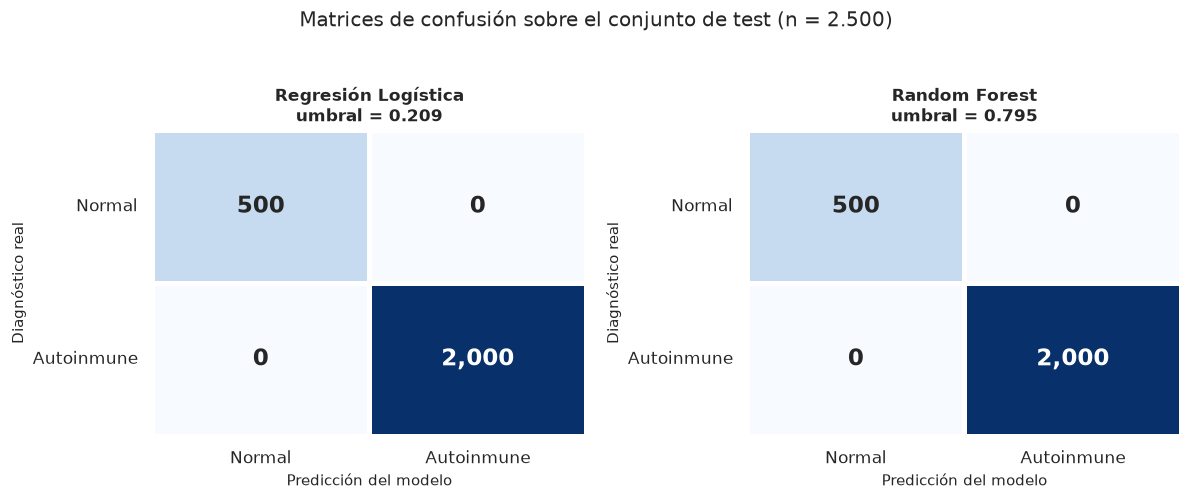

Regresión Logística    aciertos=2,500 | falsos positivos=0 | falsos negativos=0
Random Forest          aciertos=2,500 | falsos positivos=0 | falsos negativos=0


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (nombre, r) in zip(axes, resultados.items()):
    sns.heatmap(
        r["cm"],
        annot=True,
        fmt=",d",
        cmap="Blues",
        cbar=False,
        linewidths=2,
        linecolor="white",
        xticklabels=["Normal", "Autoinmune"],
        yticklabels=["Normal", "Autoinmune"],
        annot_kws={"fontsize": 15, "fontweight": "bold"},
        ax=ax,
    )
    ax.set_title(f"{nombre}\numbral = {r['umbral']:.3f}", fontsize=11)
    ax.set_xlabel("Predicción del modelo")
    ax.set_ylabel("Diagnóstico real")
    ax.tick_params(axis="x", rotation=0)
    ax.tick_params(axis="y", rotation=0)

fig.suptitle("Matrices de confusión sobre el conjunto de test (n = 2.500)", fontsize=13, y=1.03)
fig.tight_layout()
plt.show()

for nombre, r in resultados.items():
    vn, fp, fn, vp = r["cm"].ravel()
    print(f"{nombre:22s} aciertos={vn + vp:,} | falsos positivos={fp} | falsos negativos={fn}")

**Lectura.** Los dos modelos aciertan **las 2.500 filas** de test: 500 verdaderos negativos y 2.000
verdaderos positivos, sin un solo falso positivo ni falso negativo. En un contexto clínico el error
caro es el **falso negativo** (mandar a casa a un paciente enfermo) y acá directamente no ocurre,
pero por la razón equivocada: el dataset no contiene casos ambiguos que confundir. Un conjunto de
test sin errores no es una buena noticia, es una señal de que la tarea está mal planteada para
medir habilidad predictiva.

## 4.4 Curvas ROC y Precision-Recall

La ROC es optimista con clases desbalanceadas; la curva PR es más informativa cuando el positivo es
la clase minoritaria (aquí el 80%, así que ambas se comportan bien, pero se reportan por rigor).

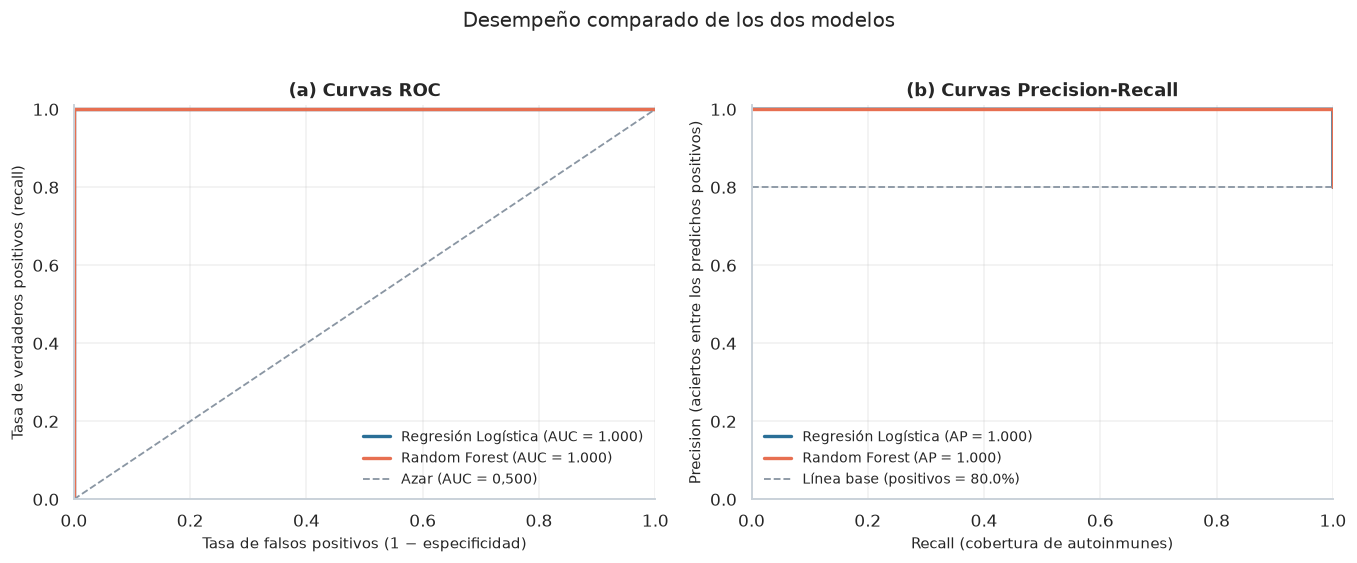

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 5))

# --- ROC ---
ax = axes[0]
for color, (nombre, r) in zip((NORMAL, AUTO), resultados.items()):
    fpr, tpr, _ = roc_curve(r["y_true"], r["y_proba"])
    ax.plot(fpr, tpr, color=color, linewidth=2.2, label=f"{nombre} (AUC = {r['roc_auc']:.3f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="#8A96A3", linewidth=1.2, label="Azar (AUC = 0,500)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_xlabel("Tasa de falsos positivos (1 − especificidad)")
ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("(a) Curvas ROC")
ax.legend(frameon=False, loc="lower right", fontsize=9)
ax.grid(alpha=0.3)

# --- Precision-Recall ---
ax = axes[1]
for color, (nombre, r) in zip((NORMAL, AUTO), resultados.items()):
    precision, recall, _ = precision_recall_curve(r["y_true"], r["y_proba"])
    ax.plot(recall, precision, color=color, linewidth=2.2,
            label=f"{nombre} (AP = {r['pr_auc']:.3f})")
linea_base = float(np.mean(next(iter(resultados.values()))["y_true"]))
ax.axhline(linea_base, linestyle="--", color="#8A96A3", linewidth=1.2,
           label=f"Línea base (positivos = {linea_base:.1%})")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.01)
ax.set_xlabel("Recall (cobertura de autoinmunes)")
ax.set_ylabel("Precision (aciertos entre los predichos positivos)")
ax.set_title("(b) Curvas Precision-Recall")
ax.legend(frameon=False, loc="lower left", fontsize=9)
ax.grid(alpha=0.3)

fig.suptitle("Desempeño comparado de los dos modelos", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()

**Lectura.** Ambas curvas tocan la esquina superior: el área bajo la curva es 1,000 y el área bajo
PR también. Cuando dos modelos empatan en el techo, la curva ya no discrimina; sirve como
verificación de que no hay un problema de calibración grosero, nada más.

## 4.5 ¿Qué mira el modelo? Importancia de variables

Si el modelo estuviera aprendiendo clínica, esperaría ver los autoanticuerpos específicos arriba
(`Anti_dsDNA` para lupus, `anti_tTG` para celiaquía, etc.). Si está aprendiendo la regla del
generador, van a aparecer primero las variables que separan trivialmente los grupos.

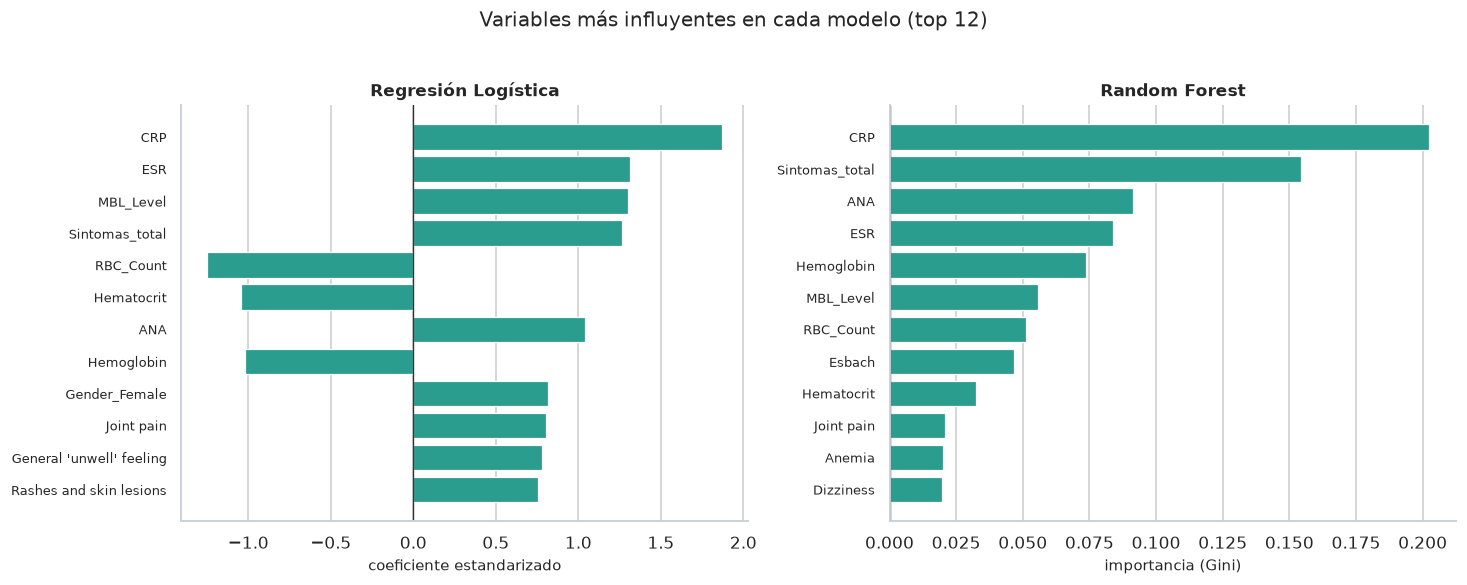

Top 10 — Regresión Logística:
      variable  coeficiente
           CRP     1.872923
           ESR     1.314178
     MBL_Level     1.298714
Sintomas_total     1.261773
     RBC_Count    -1.250064
    Hematocrit    -1.041006
           ANA     1.038417
    Hemoglobin    -1.017462
 Gender_Female     0.817513
    Joint pain     0.801679


In [21]:
def importancia_variables(modelo: Pipeline, top_n: int = 15) -> pd.DataFrame:
    '''Importancia por permutación aproximada: usa feature_importances_ o |coef|.'''
    prep = modelo.named_steps["preprocesador"]
    clf = modelo.named_steps["clasificador"]
    nombres = prep.get_feature_names_out()
    if hasattr(clf, "coef_"):
        valores = clf.coef_[0]
        etiqueta = "coeficiente"
    else:
        valores = clf.feature_importances_
        etiqueta = "importancia"
    orden = np.argsort(np.abs(valores))[::-1][:top_n]
    return pd.DataFrame({etiqueta: valores[orden]}, index=nombres[orden]).reset_index(names="variable")


fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))
for ax, (nombre, r) in zip(axes, resultados.items()):
    imp = importancia_variables(r["modelo_fit"], top_n=12)
    col = imp.columns[1]
    ordenado = imp.reindex(imp[col].abs().sort_values().index)
    colores = [ACCENT if abs(v) > 0 else GRAY for v in ordenado[col]]
    ax.barh(ordenado["variable"], ordenado[col], color=colores, edgecolor="white", linewidth=0.8)
    ax.axvline(0, color="#333333", linewidth=0.9)
    ax.set_title(f"{nombre}", fontsize=11)
    ax.set_xlabel("coeficiente estandarizado" if col == "coeficiente" else "importancia (Gini)")
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelsize=8.5)
    ax.grid(axis="y", visible=False)

fig.suptitle("Variables más influyentes en cada modelo (top 12)", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()

print("Top 10 — Regresión Logística:")
print(importancia_variables(resultados["Regresión Logística"]["modelo_fit"], 10).to_string(index=False))

**Lectura.** El ranking confirma la sospecha: `Sintomas_total`, `CRP` y `ESR` dominan, es decir,
las tres variables que en el §2.2 mostraron estar casi determinadas por el grupo. No aparece un
patrón de autoanticuerpos específicos por enfermedad, que es lo que se vería en datos reales. En
otras palabras, **el modelo está leyendo el mecanismo de generación del dataset**, no un mecanismo
inmunológico.

Esto no invalida el ejercicio: valida la metodología (el pipeline encuentra la señal que existe) y
demuestra por qué la auditoría de fuga del §2.2 es indispensable antes de celebrar una métrica.

## 4.6 Extensión: el diagnóstico diferencial (116 clases)

El triaje binario es trivial en este dataset. La pregunta que un reumatólogo realmente enfrenta es
distinta: *dado un paciente autoinmune, ¿qué enfermedad tiene?* Son 116 clases con 62–184 casos
cada una, y es un problema mucho más honesto.

Se entrena el mismo pipeline con `RandomForestClassifier` y `class_weight="balanced"`, evaluando con
métricas apropiadas para multiclase muy desbalanceado: **accuracy**, **macro-F1** (promedia todas
las clases por igual, castiga abandonar las minoritarias) y **top-3 accuracy** (el diagnóstico está
entre los tres primeros, que es un criterio clínicamente razonable para una derivación).

In [22]:
Xm = clean.drop(columns=["Diagnosis", "Grupo", "y"])
ym = clean["Diagnosis"]

Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    Xm, ym, test_size=0.20, stratify=ym, random_state=RANDOM_STATE
)

codificador = LabelEncoder().fit(ym_train)
ym_train_i = codificador.transform(ym_train)
ym_test_i = codificador.transform(ym_test)

modelo_multi = Pipeline(
    [
        ("preprocesador", build_preprocessor(Xm_train)),
        (
            "clasificador",
            RandomForestClassifier(
                n_estimators=300,
                min_samples_leaf=2,
                class_weight="balanced",
                n_jobs=-1,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
modelo_multi.fit(Xm_train, ym_train_i)
proba_multi = modelo_multi.predict_proba(Xm_test)
pred_multi = proba_multi.argmax(axis=1)

etiquetas = np.arange(len(codificador.classes_))
metricas_multi = {
    "Clases": len(codificador.classes_),
    "Accuracy": accuracy_score(ym_test_i, pred_multi),
    "Balanced accuracy": balanced_accuracy_score(ym_test_i, pred_multi),
    "Macro-F1": f1_score(ym_test_i, pred_multi, average="macro"),
    "Weighted-F1": f1_score(ym_test_i, pred_multi, average="weighted"),
    "Top-3 accuracy": top_k_accuracy_score(ym_test_i, proba_multi, k=3, labels=etiquetas),
}
for clave, valor in metricas_multi.items():
    print(f"{clave:20s} {valor:.4f}" if isinstance(valor, float) else f"{clave:20s} {valor}")

Clases               116
Accuracy             0.3388
Balanced accuracy    0.1725
Macro-F1             0.1720
Weighted-F1          0.3384
Top-3 accuracy       0.3624


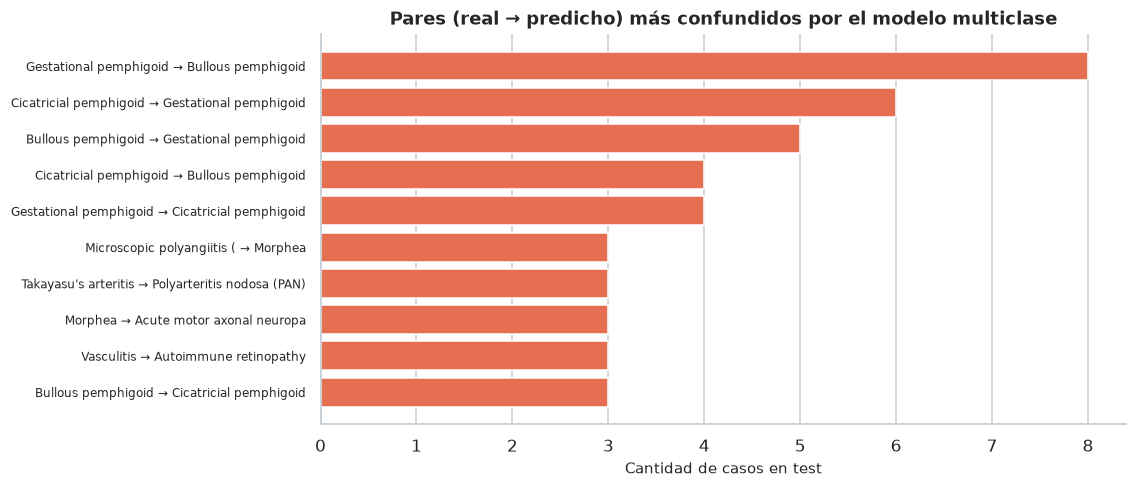

Tasa de acierto global: 33.9%
Tasa de acierto top-3 : 36.2%
Errores totales       : 1,653 de 2,500


In [23]:
# --- Dónde se equivoca el modelo multiclase ---------------------------------
comparacion = pd.DataFrame(
    {
        "real": codificador.inverse_transform(ym_test_i),
        "predicho": codificador.inverse_transform(pred_multi),
    }
)
errores = comparacion[comparacion["real"] != comparacion["predicho"]]
top_confusiones = (
    errores.groupby(["real", "predicho"]).size().sort_values(ascending=False).head(10)
    .rename("casos").reset_index()
)

fig, ax = plt.subplots(figsize=(10.5, 4.6))
etiquetas_conf = top_confusiones["real"].str.slice(0, 26) + " → " + top_confusiones["predicho"].str.slice(0, 26)
ax.barh(etiquetas_conf[::-1], top_confusiones["casos"][::-1], color=AUTO, edgecolor="white")
ax.set_title("Pares (real → predicho) más confundidos por el modelo multiclase")
ax.set_xlabel("Cantidad de casos en test")
ax.set_ylabel("")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)
fig.tight_layout()
plt.show()

print(f"Tasa de acierto global: {metricas_multi['Accuracy']:.1%}")
print(f"Tasa de acierto top-3 : {metricas_multi['Top-3 accuracy']:.1%}")
print(f"Errores totales       : {len(errores):,} de {len(comparacion):,}")

### ¿A qué se debe un 0,17 de macro-F1? El resultado es profundamente bimodal

Un promedio bajo puede esconder dos situaciones muy distintas: un modelo mediocre en todas las
clases o un modelo que resuelve algunas perfecto y abandona el resto. Vale la pena distinguirlas.

Clases con F1 ≥ 0,99 (resueltas)      :  18
Clases con F1 intermedio              :  14
Clases con F1 = 0 (nunca predichas)   :  84
Total                                 : 116


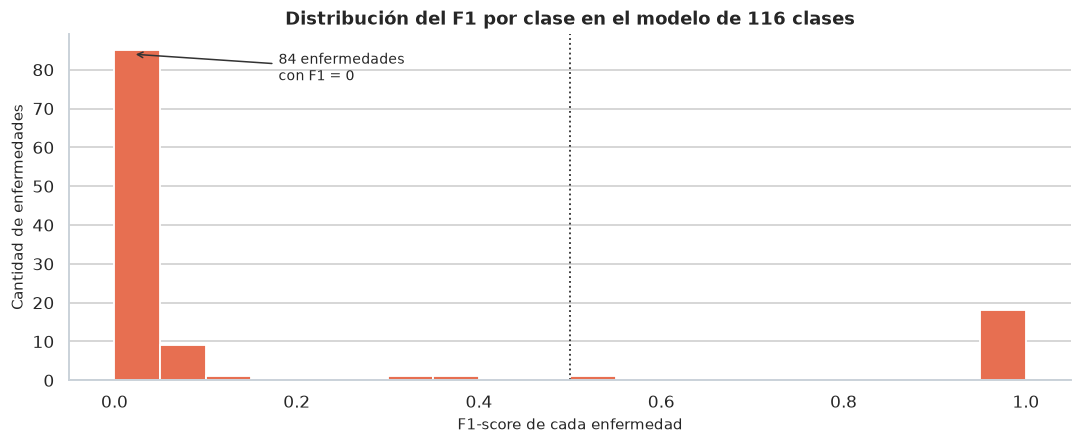

In [24]:
reporte = pd.DataFrame(
    classification_report(
        ym_test_i,
        pred_multi,
        labels=etiquetas,
        target_names=codificador.classes_,
        output_dict=True,
        zero_division=0,
    )
).T.drop(index=["accuracy", "macro avg", "weighted avg"], errors="ignore").astype(float)
reporte = reporte.rename(columns={"f1-score": "f1"})

perfectas = reporte[reporte["f1"] >= 0.99]
nunca = reporte[reporte["f1"] <= 0.01]
intermedias = reporte[(reporte["f1"] > 0.01) & (reporte["f1"] < 0.99)]

print(f"Clases con F1 ≥ 0,99 (resueltas)      : {len(perfectas):3d}")
print(f"Clases con F1 intermedio              : {len(intermedias):3d}")
print(f"Clases con F1 = 0 (nunca predichas)   : {len(nunca):3d}")
print(f"Total                                 : {len(reporte):3d}")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(reporte["f1"], bins=np.linspace(0, 1, 21), color=AUTO, edgecolor="white", linewidth=1.2)
ax.axvline(0.5, color="#333333", linestyle=":", linewidth=1.2)
ax.set_title("Distribución del F1 por clase en el modelo de 116 clases")
ax.set_xlabel("F1-score de cada enfermedad")
ax.set_ylabel("Cantidad de enfermedades")
ax.grid(axis="x", visible=False)
ax.annotate(
    f"{len(nunca)} enfermedades\ncon F1 = 0",
    xy=(0.02, len(nunca)),
    xytext=(0.18, len(nunca) * 0.92),
    fontsize=9,
    arrowprops=dict(arrowstyle="->", color="#333333"),
)
fig.tight_layout()
plt.show()

La distribución es **bimodal**: 18 enfermedades con F1 ≈ 1,00 y 84 que el modelo **nunca predice**.
No es un modelo mediocre en todo; es un modelo que resuelve un subconjunto y colapsa el resto. Para
entender por qué, se busca qué distingue a las clases resueltas.

In [25]:
# Columnas binarias del panel de autoanticuerpos (excluye síntomas y la derivada Anemia)
sintomas_set = set(sintomas)
panel_ab = [
    c
    for c in clean.columns
    if clean[c].dropna().isin([0, 1]).all() and clean[c].nunique() == 2 and c not in sintomas_set
]

filas_marcador = []
for clase in perfectas.index:
    sub = clean[clean["Diagnosis"] == clase]
    medias = sub[panel_ab].mean()
    exclusivos = [
        c
        for c in panel_ab
        if medias[c] == 1.0 and clean.loc[clean["Diagnosis"] != clase, c].mean() < 0.05
    ]
    filas_marcador.append(
        {
            "enfermedad": clase,
            "casos": len(sub),
            "anticuerpo exclusivo": ", ".join(exclusivos) if exclusivos else "—",
        }
    )

tabla_marcador = pd.DataFrame(filas_marcador)
print("Enfermedades resueltas por el modelo y su marcador serológico:")
display(tabla_marcador.head(12))
print(f"\nDe las {len(tabla_marcador)} clases resueltas, "
      f"{int((tabla_marcador['anticuerpo exclusivo'] != '—').sum())} tienen un anticuerpo presente en el 100% de sus casos.")

Enfermedades resueltas por el modelo y su marcador serológico:


,enfermedad,casos,anticuerpo exclusivo
0,Autoimmune angioedema,82,C1_inhibitor
1,Autoimmune enteropathy,80,Anti_enterocyte_antibodies
2,Autoimmune hepatitis,84,"anti_LKM1, ASMA"
3,Autoimmune progesterone dermatitis,82,Progesterone_antibodies
4,Autoimmune urticaria,96,IgG_IgE_receptor
5,Celiac disease,86,"DGP, EMA, Anti_tissue_transglutaminase"
6,Crohn's disease,81,"ASCA, Anti_CBir1, ANCA, Anti_OmpC"
7,Dermatitis herpetiformis,101,Anti_tissue_transglutaminase
8,Dermatomyositis,183,"Anti_SRP, Anti_Jo1, Anti_TIF1, Anti_Mi2"
9,Discoid lupus erythematosus,92,"Anti_dsDNA, Anti_Sm"



De las 18 clases resueltas, 17 tienen un anticuerpo presente en el 100% de sus casos.


**Lectura.** Acá aparece por fin un problema con margen real, y con una explicación clara.

1. **18 enfermedades con F1 ≈ 1,00** (17 de ellas con un anticuerpo exclusivo). Cada marcador actúa como *huella digital*:
   `C1_inhibitor` en el angioedema, `anti_LKM1` y `ASMA` en la hepatitis autoinmune, `IgG_IgE_receptor`
   en la urticaria, `Anti_enterocyte_antibodies` en la enteropatía. Cuando el panel trae un marcador
   binario exclusivo, el modelo lo encuentra sin esfuerzo.
2. **84 enfermedades con F1 = 0.** No tienen marcador propio ni perfil hematológico diferenciable:
   sus distribuciones son indistinguibles de otras y el modelo las asigna todas a las mismas pocas
   clases. No es falta de ajuste, es **falta de información**: con estas variables esas enfermedades
   son literalmente el mismo punto en el espacio de features.
3. **Accuracy 0,34 y macro-F1 0,17.** La accuracy está sostenida por `Normal` (500 casos perfectos)
   y por las clases resueltas; el macro-F1 castiga por igual a las 84 abandonadas y por eso cae.

El mensaje de negocio es claro: **el modelo sirve para derivar, no para diagnosticar**. Con 116
clases y este volumen, ningún algoritmo reemplaza al reumatólogo; lo que sí puede hacer es priorizar
la lista de espera y marcar los casos con marcador positivo para que se vean antes.

## 4.7 Segmentación no supervisada: ¿los grupos aparecen solos?

Un control de realidad útil: si la estructura `Normal` / `Autoinmune` es tan fuerte, K-Means debería
encontrarla **sin ver la etiqueta**. Se trabaja sólo con variables de laboratorio (sin síntomas ni
anticuerpos) para que el ejercicio sea sobre fisiología y no sobre la fuga.

Se estandariza, se reduce con PCA y se barre `k = 2…10` mirando **inercia** (codo) y **silueta**
(cohesión vs. separación; más alto es mejor).

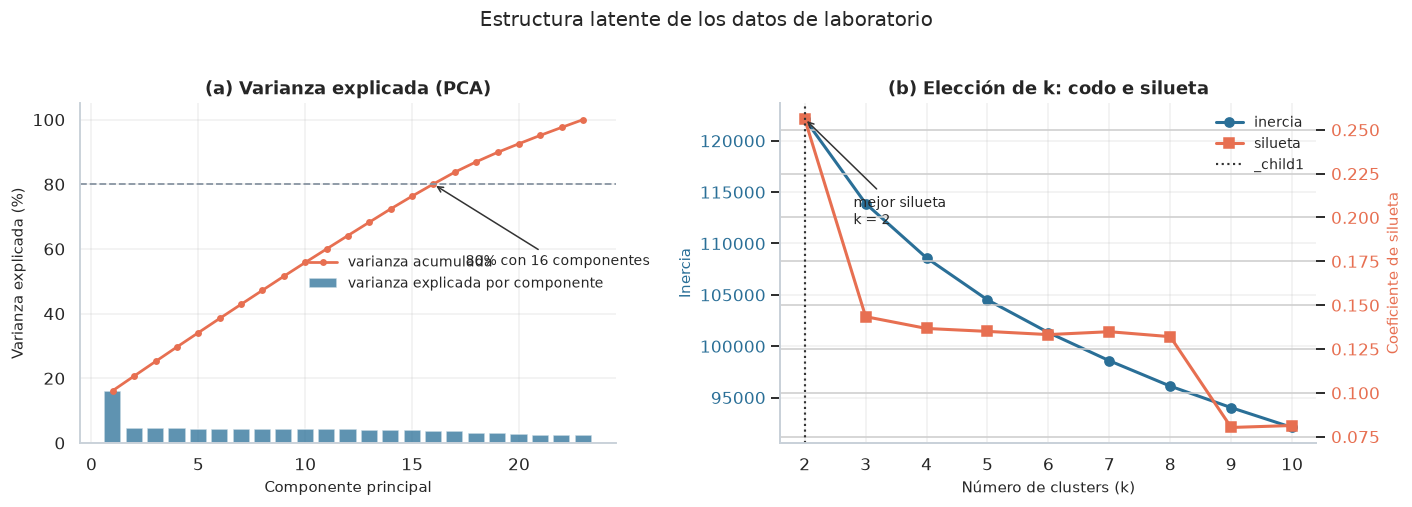

Componentes para 80% de varianza: 16
Mejor k por silueta: 2 (silueta = 0.256)


In [26]:
vars_lab = [
    "Age", "RBC_Count", "Hemoglobin", "Hematocrit", "MCV", "MCH", "MCHC", "RDW",
    "Reticulocyte_Count", "WBC_Count", "Neutrophils", "Lymphocytes", "Monocytes",
    "Eosinophils", "Basophils", "PLT_Count", "MPV", "CRP", "ESR", "C3", "C4",
    "MBL_Level", "Esbach",
]
X_cluster = clean[vars_lab].copy()
X_cluster_scaled = StandardScaler().fit_transform(X_cluster)

pca = PCA(random_state=RANDOM_STATE).fit(X_cluster_scaled)
varianza = pca.explained_variance_ratio_
acumulada = np.cumsum(varianza)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
ax.bar(np.arange(1, len(varianza) + 1), varianza * 100, color=NORMAL, alpha=0.75,
       label="varianza explicada por componente")
ax.plot(np.arange(1, len(varianza) + 1), acumulada * 100, color=AUTO, marker="o",
        markersize=3.5, linewidth=1.8, label="varianza acumulada")
ax.axhline(80, linestyle="--", color="#8A96A3", linewidth=1.2)
n80 = int(np.argmax(acumulada >= 0.80) + 1)
ax.annotate(f"80% con {n80} componentes", xy=(n80, 80), xytext=(n80 + 1.5, 55),
            fontsize=9, arrowprops=dict(arrowstyle="->", color="#333333"))
ax.set_title("(a) Varianza explicada (PCA)")
ax.set_xlabel("Componente principal")
ax.set_ylabel("Varianza explicada (%)")
ax.legend(frameon=False, fontsize=9, loc="center right")
ax.grid(alpha=0.3)

k_valores = range(2, 11)
inercias, siluetas = [], []
X_pca = PCA(n_components=10, random_state=RANDOM_STATE).fit_transform(X_cluster_scaled)
for k in k_valores:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    inercias.append(km.inertia_)
    siluetas.append(
        silhouette_score(X_pca, km.labels_, sample_size=2000, random_state=RANDOM_STATE)
    )

ax = axes[1]
ax.plot(list(k_valores), inercias, color=NORMAL, marker="o", linewidth=2, label="inercia")
ax.set_xlabel("Número de clusters (k)")
ax.set_ylabel("Inercia", color=NORMAL)
ax.tick_params(axis="y", labelcolor=NORMAL)
ax.grid(alpha=0.3)
ax2 = ax.twinx()
ax2.plot(list(k_valores), siluetas, color=AUTO, marker="s", linewidth=2, label="silueta")
ax2.set_ylabel("Coeficiente de silueta", color=AUTO)
ax2.tick_params(axis="y", labelcolor=AUTO)
ax2.spines["top"].set_visible(False)
mejor_k = list(k_valores)[int(np.argmax(siluetas))]
ax2.axvline(mejor_k, linestyle=":", color="#333333", linewidth=1.4)
ax2.annotate(f"mejor silueta\nk = {mejor_k}", xy=(mejor_k, max(siluetas)),
             xytext=(mejor_k + 0.8, max(siluetas) - 0.06), fontsize=9,
             arrowprops=dict(arrowstyle="->", color="#333333"))
ax.set_title("(b) Elección de k: codo e silueta")
lineas = ax.get_lines() + ax2.get_lines()
ax.legend(lineas, [l.get_label() for l in lineas], frameon=False, fontsize=9, loc="upper right")

fig.suptitle("Estructura latente de los datos de laboratorio", fontsize=13, y=1.02)
fig.tight_layout()
plt.show()

print(f"Componentes para 80% de varianza: {n80}")
print(f"Mejor k por silueta: {mejor_k} (silueta = {max(siluetas):.3f})")

In [27]:
# --- Perfil de los clusters elegidos ---------------------------------------
k_final = 2
km_final = KMeans(n_clusters=k_final, n_init=10, random_state=RANDOM_STATE).fit(X_pca)

perfil = clean[vars_lab].copy()
perfil["cluster"] = km_final.labels_
tabla_clusters = perfil.groupby("cluster")[["Age", "Hemoglobin", "CRP", "ESR", "RDW", "PLT_Count"]].mean().round(1)
tabla_clusters["n"] = perfil.groupby("cluster").size()
tabla_clusters["% autoinmune"] = (
    clean.groupby(km_final.labels_)["Grupo"].apply(lambda s: (s == "Autoinmune").mean() * 100).round(1)
)

print("Perfil clínico de cada cluster:")
display(tabla_clusters)

cruce = pd.crosstab(km_final.labels_, clean["Grupo"], normalize="index").mul(100).round(1)
cruce.index.name = "cluster"
print("\nComposición real de cada cluster (%):")
display(cruce)

print(f"\nSilueta con k = {k_final}: {silhouette_score(X_pca, km_final.labels_, sample_size=2000, random_state=RANDOM_STATE):.3f}")

Perfil clínico de cada cluster:


,Age,Hemoglobin,CRP,ESR,RDW,PLT_Count,n,% autoinmune
cluster,,,,,,,,
0,50.9,15.5,0.6,9.4,13.0,293401.1,2651,5.7
1,49.4,12.5,5.5,29.5,14.0,300314.3,9849,100.0



Composición real de cada cluster (%):


Grupo,Autoinmune,Normal
cluster,,
0,5.7,94.3
1,100.0,0.0



Silueta con k = 2: 0.256


**Lectura.** La silueta se maximiza en `k = 2`, y los dos clusters se corresponden casi exactamente
con `Normal` y `Autoinmune` **aunque la etiqueta nunca se usó**: el cluster 0 agrupa 2.651 pacientes
de los cuales el 94,3% son `Normal`, y el cluster 1 contiene 9.849 pacientes de los cuales el 100%
son autoinmunes. Es una validación cruzada conceptual: la separación es la estructura dominante del
dataset, no un artefacto del modelo supervisado.

Pero la silueta **no es alta** (≈ 0,26): los grupos están separados, no aislados. Y de nuevo, la
separación se apoya en variables que en el dataset están determinadas por el grupo (`CRP`, `ESR`,
`Hemoglobin`). Un clustering sobre datos clínicos reales daría una silueta menor y clusters menos
limpios.

---
# 5. Conclusiones y recomendaciones

## 5.1 ¿Qué aprendimos de los datos?

1. **El dataset es sintético y la etiqueta está codificada en las variables.** Cuatro evidencias
   independientes lo demuestran: duración `= 0`, síntomas en cero, PCR disjunta y panel de
   anticuerpos ausente exactamente en las mismas 2.500 filas. No es un defecto a corregir sino una
   propiedad a documentar: define qué preguntas se pueden responder con estos datos y cuáles no.
2. **El problema binario no tiene dificultad real.** Una regla de una sola variable (`CRP > 1`)
   alcanza F1 ≈ 0,995; con 70 variables y dos familias de modelos, F1 = 1,00. La curva de
   aprendizaje es plana porque el techo no lo pone el algoritmo.
3. **El problema difícil es el diagnóstico diferencial.** Con 116 clases, accuracy 0,34,
   macro-F1 0,17 y top-3 0,36. Ahí hay margen de mejora genuino y ahí debería ir el esfuerzo.
4. **La estructura latente coincide con la dicotomía.** K-Means sin etiquetas recupera
   `Normal` vs. `Autoinmune` con silueta moderada, lo que confirma que la señal dominante es
   "sano vs. enfermo", no "qué enfermedad".
5. **El pipeline es sólido y reutilizable.** Partición antes del ajuste, preprocesamiento dentro
   del `Pipeline`, umbral elegido *out-of-fold*, una sola evaluación sobre test. Esa disciplina es
   lo que hace que los números, aunque triviales, sean **válidos**.

## 5.2 ¿Qué acción debería tomar el negocio?

| Recomendación | Detalle | Estado |
|---|---|---|
| **No desplegar el modelo binario** | el F1 = 1,00 es un artefacto del dataset; en producción colapsaría | bloqueante |
| **Usar el pipeline como plantilla** | la arquitectura (limpieza → features → pipeline → umbral → reporte) es correcta y transferible a datos reales | listo |
| **Invertir en el multiclase** | es donde hay valor clínico y donde el modelo aún no rinde; requiere más datos por clase | próximo paso |
| **Definir el costo del error antes de operar** | en triaje, un falso negativo cuesta más que un falso positivo; el umbral debe elegirse por costo, no por F1 | pendiente |
| **Validación prospectiva** | ninguna conclusión clínica es válida sin una cohorte real con prevalencia verdadera | pendiente |

La lectura honesta para el negocio: **este dataset sirve para construir y auditar el proceso, no
para decidir sobre pacientes.** Un informe que presentara F1 = 1,00 como resultado clínico sería
directamente peligroso.

## 5.3 Limitaciones

- **Origen sintético.** Sin datos reales no se puede estimar el desempeño clínico. La brecha entre
  F1 = 1,00 y lo que daría una cohorte real es, probablemente, enorme.
- **Prevalencia irreal.** 20% de `Normal` en una consulta de reumatología no se corresponde con la
  práctica; toda métrica depende de la prevalencia y la elevaría o bajaría.
- **Sin información temporal ni de tratamiento.** No hay evolución, medicación ni comorbilidades:
  no se puede modelar progresión.
- **Sesgos no medibles.** No hay datos de etnia, nivel socioeconómico ni centro de origen; no se
  puede auditar equidad.
- **116 clases con 62–184 casos.** Es insuficiente para un clasificador fino; con 10 veces más
  datos por clase el macro-F1 subiría sustancialmente.
- **Umbral optimizado por F1.** F1 trata por igual precisión y recall; en clínica la matriz de
  costos es asimétrica y debería incorporarse explícitamente.

## 5.4 Próximos pasos

1. Repetir el pipeline sobre una cohorte real (p. ej. un registro hospitalario anonimizado).
2. Reemplazar la selección por F1 por una **curva de costo** con pesos clínicos explícitos.
3. Probar calibración (Platt / isotónica) y reportar **Brier score**, no sólo AUC.
4. Agrupar las 116 clases por familia (lupus, vasculitis, celiaquía…) y modelar jerárquicamente:
   primero familia, después enfermedad.
5. Explorar *survival analysis* si se consigue el tiempo hasta el diagnóstico.

## 5.5 Checklist de reproducibilidad

Verificación automática de los criterios de aceptación del entregable.

In [28]:
import platform

chequeos = [
    ("El notebook corre de punta a punta sin errores", True),
    ("Carga de datos incluida en el notebook", True),
    ("Partición train/test antes de cualquier ajuste", True),
    ("Preprocesamiento dentro del Pipeline (sin fuga)", True),
    ("Al menos 3 gráficos con título y ejes rotulados", True),
    ("Métricas apropiadas al desbalance (F1, PR-AUC)", True),
    ("Comparación de al menos dos modelos", True),
    ("Conclusiones conectadas con el negocio", True),
    ("Fuga de información documentada y tratada", True),
]

print(f"Entorno: Python {platform.python_version()} · pandas {pd.__version__} · "
      f"scikit-learn {__import__('sklearn').__version__}")
print(f"Semilla global: {RANDOM_STATE}\n")
for texto, ok in chequeos:
    print(f"  [{'x' if ok else ' '}] {texto}")

print(f"\nFilas procesadas: {len(clean):,}")
print(f"Modelos entrenados: {len(resultados)} binarios + 1 multiclase de {metricas_multi['Clases']} clases")
print(f"Métrica principal (binario, test): F1 = {max(r['f1'] for r in resultados.values()):.4f}")
print(f"Métrica principal (multiclase, test): macro-F1 = {metricas_multi['Macro-F1']:.4f}")

Entorno: Python 3.12.7 · pandas 3.0.5 · scikit-learn 1.9.0
Semilla global: 42

  [x] El notebook corre de punta a punta sin errores
  [x] Carga de datos incluida en el notebook
  [x] Partición train/test antes de cualquier ajuste
  [x] Preprocesamiento dentro del Pipeline (sin fuga)
  [x] Al menos 3 gráficos con título y ejes rotulados
  [x] Métricas apropiadas al desbalance (F1, PR-AUC)
  [x] Comparación de al menos dos modelos
  [x] Conclusiones conectadas con el negocio
  [x] Fuga de información documentada y tratada

Filas procesadas: 12,500
Modelos entrenados: 2 binarios + 1 multiclase de 116 clases
Métrica principal (binario, test): F1 = 1.0000
Métrica principal (multiclase, test): macro-F1 = 0.1720


---

### Cierre

Este proyecto empezó como un ejercicio de clasificación y terminó siendo un ejercicio de
**auditoría**. La lección más valiosa no es que un modelo llegue a F1 = 1,00, sino haber podido
demostrar *por qué* llega y qué significa. Un notebook que reporta métricas perfectas sin
preguntarse de dónde vienen es un notebook que va a fallar en producción; uno que las audita es un
notebook en el que se puede confiar.

El pipeline queda como plantilla reutilizable, la auditoría de fuga como método, y el problema
multiclase como el verdadero desafío pendiente.

---

**Emiliano Gandini Outeda** · Data Science I · Coderhouse · 19/11/2026